# Life-stage polities: results (whole database)
## Table 10: Share of each life stage assigned by each Wikidata field and method

In [ ]:
import sys
from pathlib import Path

import duckdb
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import show_table

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
EXPORT = Path('../../data/enriched_parquets/individual_life_stage_polities')
STAGES = ['pre_active', 'active', 'post_active']
FIELDS = ['birthplace', 'educated at', 'residence', 'citizenship', 'work location', 'employer', 'position held', 'deathplace', 'not found']
METHODS = {'URL': 'Wikipedia Url', 'coordinates': 'Center coordinates', '—': '—'}
MOVERS = {  # widely known individuals across regions and periods whose moves show across stages
    'Q8011': 'Avicenna', 'Q9294': 'Ibn Khaldun', 'Q9215': 'Sigmund Freud', 'Q9036': 'Nikola Tesla',
    'Q7186': 'Marie Curie', 'Q6882': 'James Joyce', 'Q882': 'Charlie Chaplin', 'Q5809': 'Che Guevara',
}
MAX_POLITIES = 3  # an example with more polities in one stage does not fit the table

In [2]:
stages = pl.read_parquet(EXPORT / 'batch_*.parquet', columns=['qid', 'stage', 'wikidata_field', 'method'])
print(f"{stages['qid'].n_unique():,} individuals, {stages.height:,} stages")

3,795,438 individuals, 10,570,914 stages


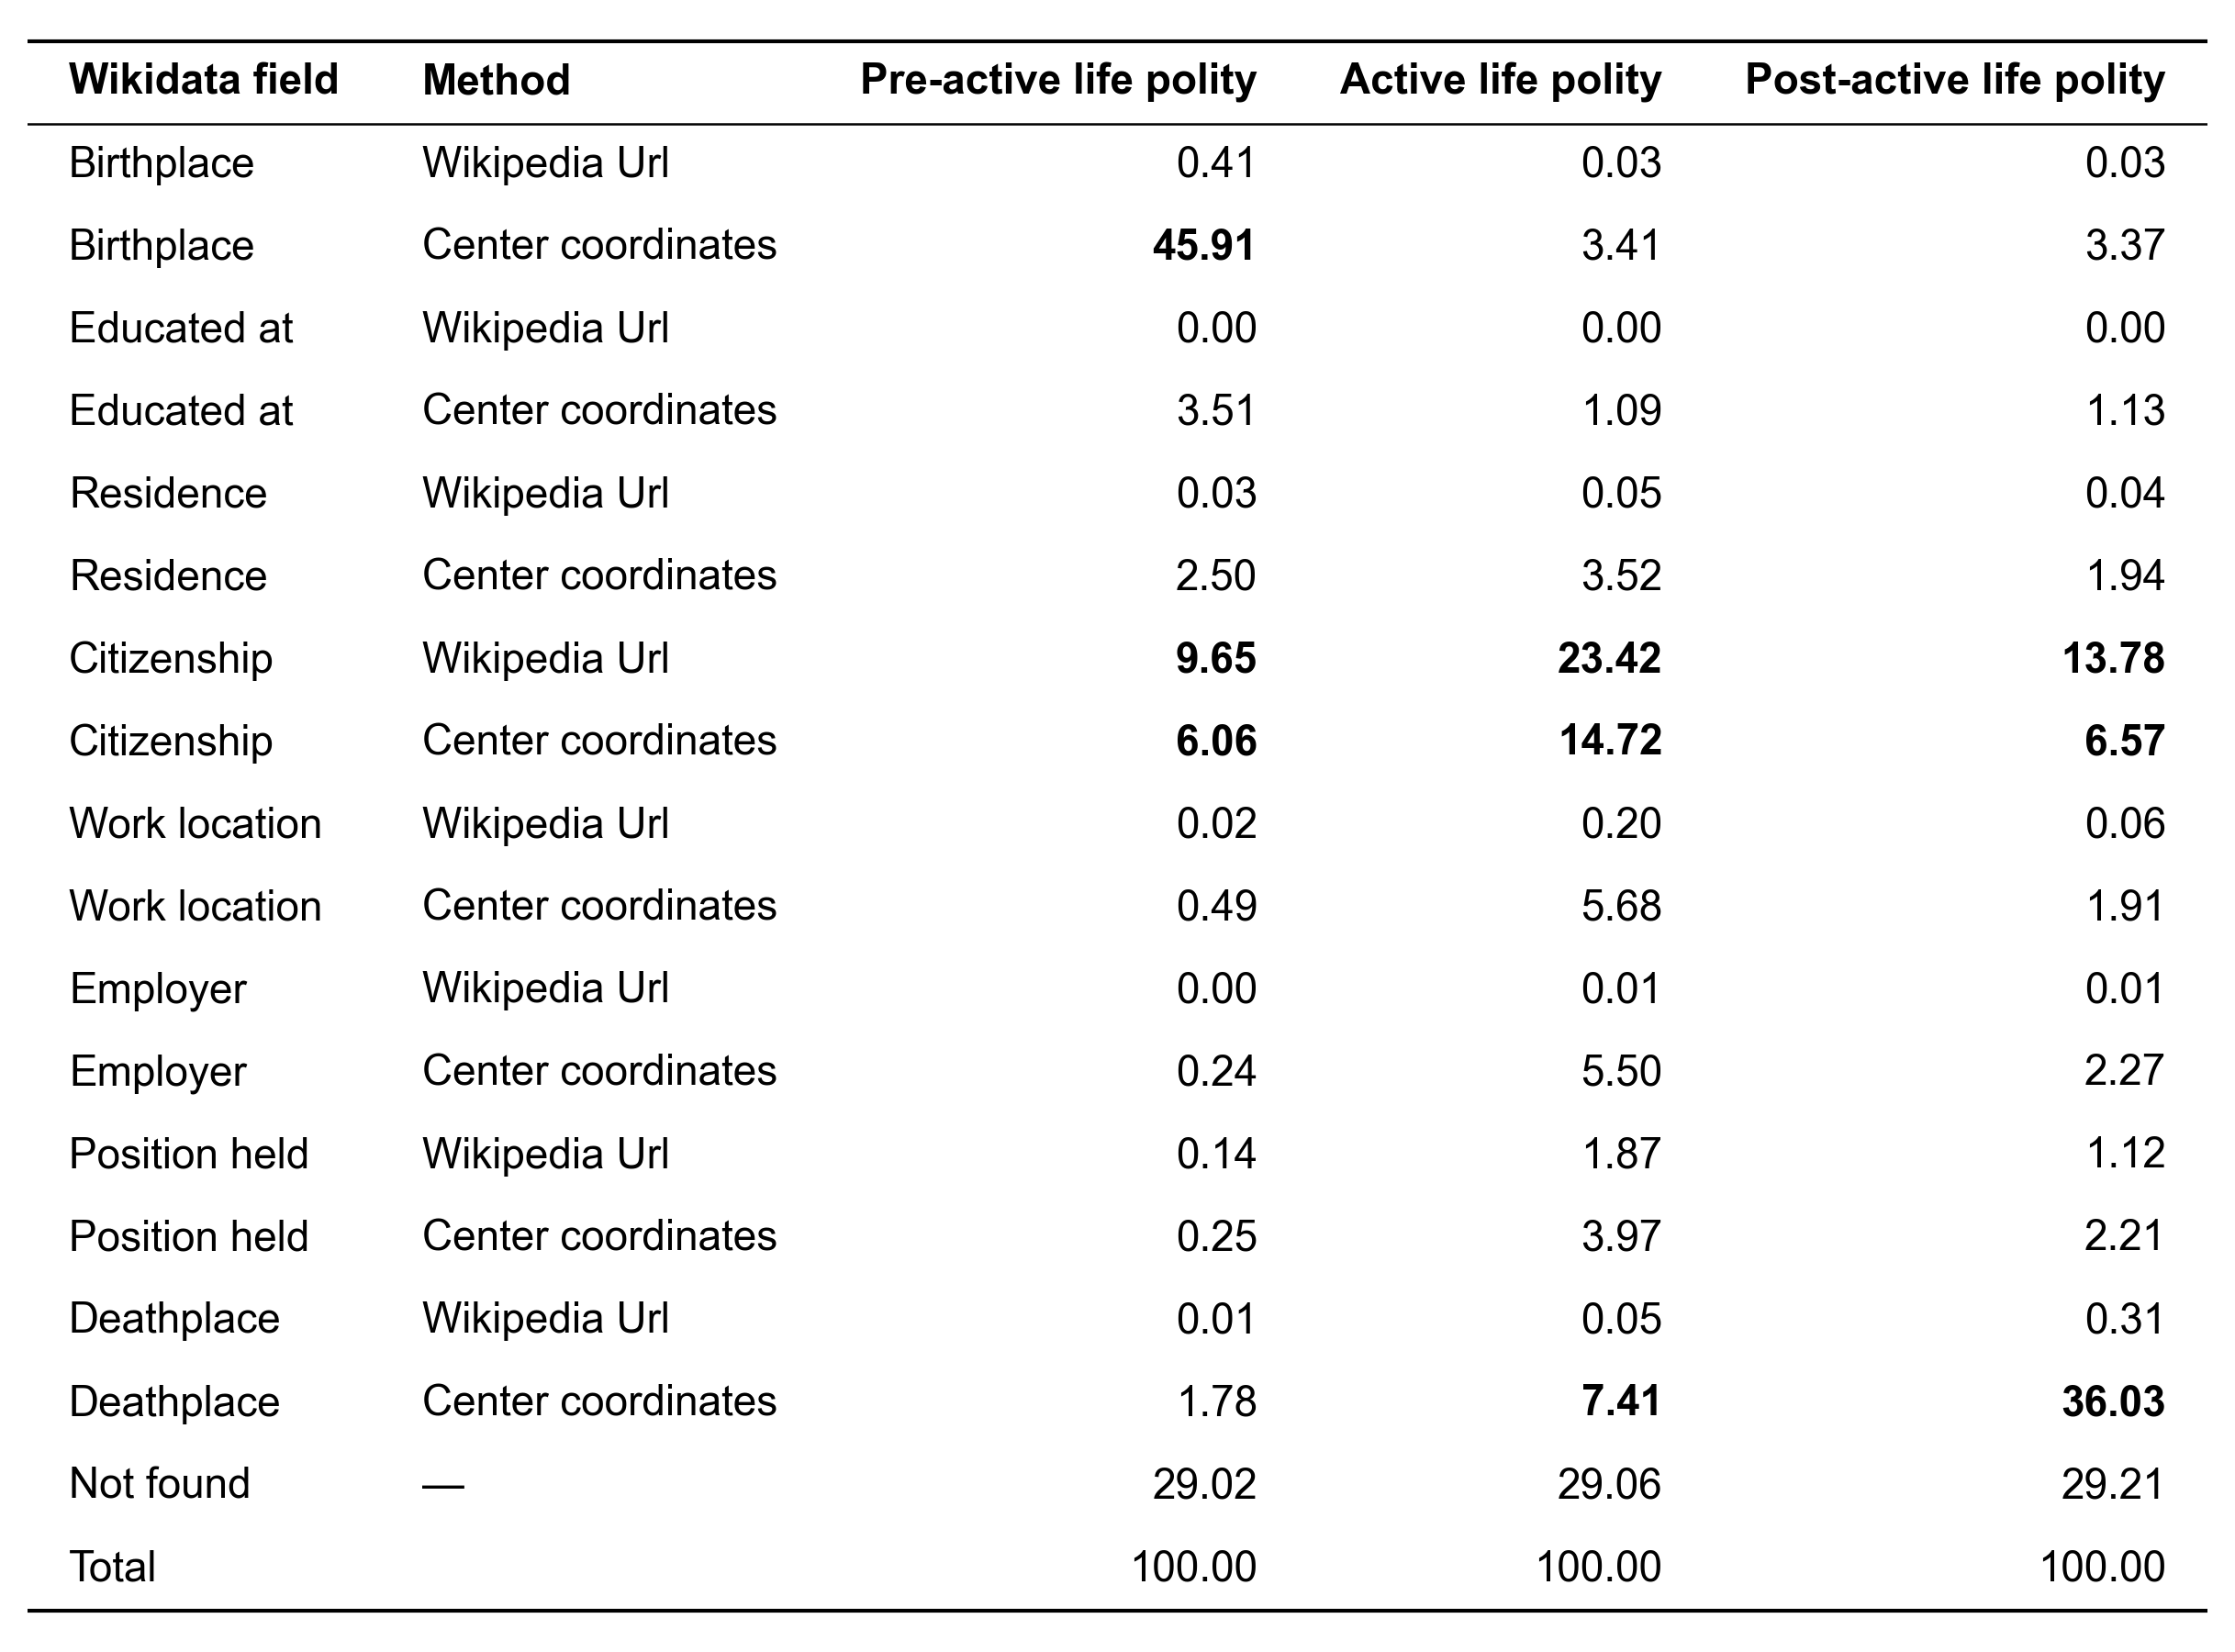

In [3]:
found_by = (
    stages.with_columns(
        field=pl.col('wikidata_field').fill_null('not found'),
        method=pl.col('method').fill_null('—'),
        individuals=pl.len().over('stage'),
    )
    .group_by('stage', 'field', 'method').agg(share=100 * pl.len() / pl.col('individuals').first())
    .pivot(on='stage', index=['field', 'method'], values='share')
    .with_columns(pl.col(STAGES).fill_null(0.0))
    .sort(pl.col('field').replace_strict({name: rank for rank, name in enumerate(FIELDS)}), pl.col('method').replace_strict({name: rank for rank, name in enumerate(METHODS)}))
    .select('field', 'method', *STAGES)
)
total = found_by.select(pl.lit('total').alias('field'), pl.lit('').alias('method'), pl.col(STAGES).sum())
columns = {'pre_active': 'Pre-active life polity', 'active': 'Active life polity', 'post_active': 'Post-active life polity'}
ranked = found_by.with_columns(pl.when(pl.col('field') == 'not found').then(None).otherwise(pl.col(stage)).alias(stage) for stage in STAGES)
top_three = {(row, columns[stage]) for stage in STAGES for row in ranked[stage].arg_sort(descending=True, nulls_last=True)[:3].to_list()}

table = pl.concat([found_by, total]).with_columns(
    pl.col('field').str.slice(0, 1).str.to_uppercase() + pl.col('field').str.slice(1),
    pl.col('method').replace(METHODS),
    pl.col(STAGES).map_elements(lambda share: f'{share:.2f}' if share else '', return_dtype=pl.String),
)
show_table(table.rename({'field': 'Wikidata field', 'method': 'Method', **columns}), bold_cells=top_three)

In [ ]:
connection = duckdb.connect(DB_PATH, read_only=True)
columns = {'pre_active': 'Pre-active life polity', 'active': 'Active life polity', 'post_active': 'Post-active life polity'}


def life_stage_table(chosen):
    dates = connection.sql(f'''
        SELECT entity.qid AS qid, birth_date.year AS birth, death_date.year AS death
        FROM individual_enriched
        WHERE entity.qid IN {tuple(chosen)} AND birth_date.iso IS NOT NULL AND death_date.iso IS NOT NULL
    ''').pl()
    assert dates.height == len(chosen), 'an example has an imputed birth or death date'
    example_stages = (
        pl.read_parquet(EXPORT / 'batch_*.parquet', columns=['qid', 'stage', 'start_year', 'end_year', 'polities'])
        .filter(pl.col('qid').is_in(list(chosen)), pl.col('polities').list.len() > 0)
    )
    assert example_stages['polities'].list.len().max() <= MAX_POLITIES, 'an example has more than three polities in a stage'
    examples = (
        example_stages.with_columns(cell=pl.format('{} ({}–{})', pl.col('polities').list.join('; '), 'start_year', 'end_year'))
        .pivot(on='stage', index='qid', values='cell')
    )
    people = (
        dates.join(examples, on='qid', how='left')
        .with_columns(pl.col(stage).fill_null('—') if stage in examples.columns else pl.lit('—').alias(stage) for stage in STAGES)
        .with_columns(name=pl.col('qid').replace_strict(chosen), life=pl.format('{}–{}', 'birth', 'death'))
        .sort('birth')
    )
    show_table(people.select(pl.col('name').alias('Individual'), pl.col('life').alias('Life'), *[pl.col(stage).alias(columns[stage]) for stage in STAGES]), font_size=10)

## Table 11: Polities assigned at each life stage to example individuals

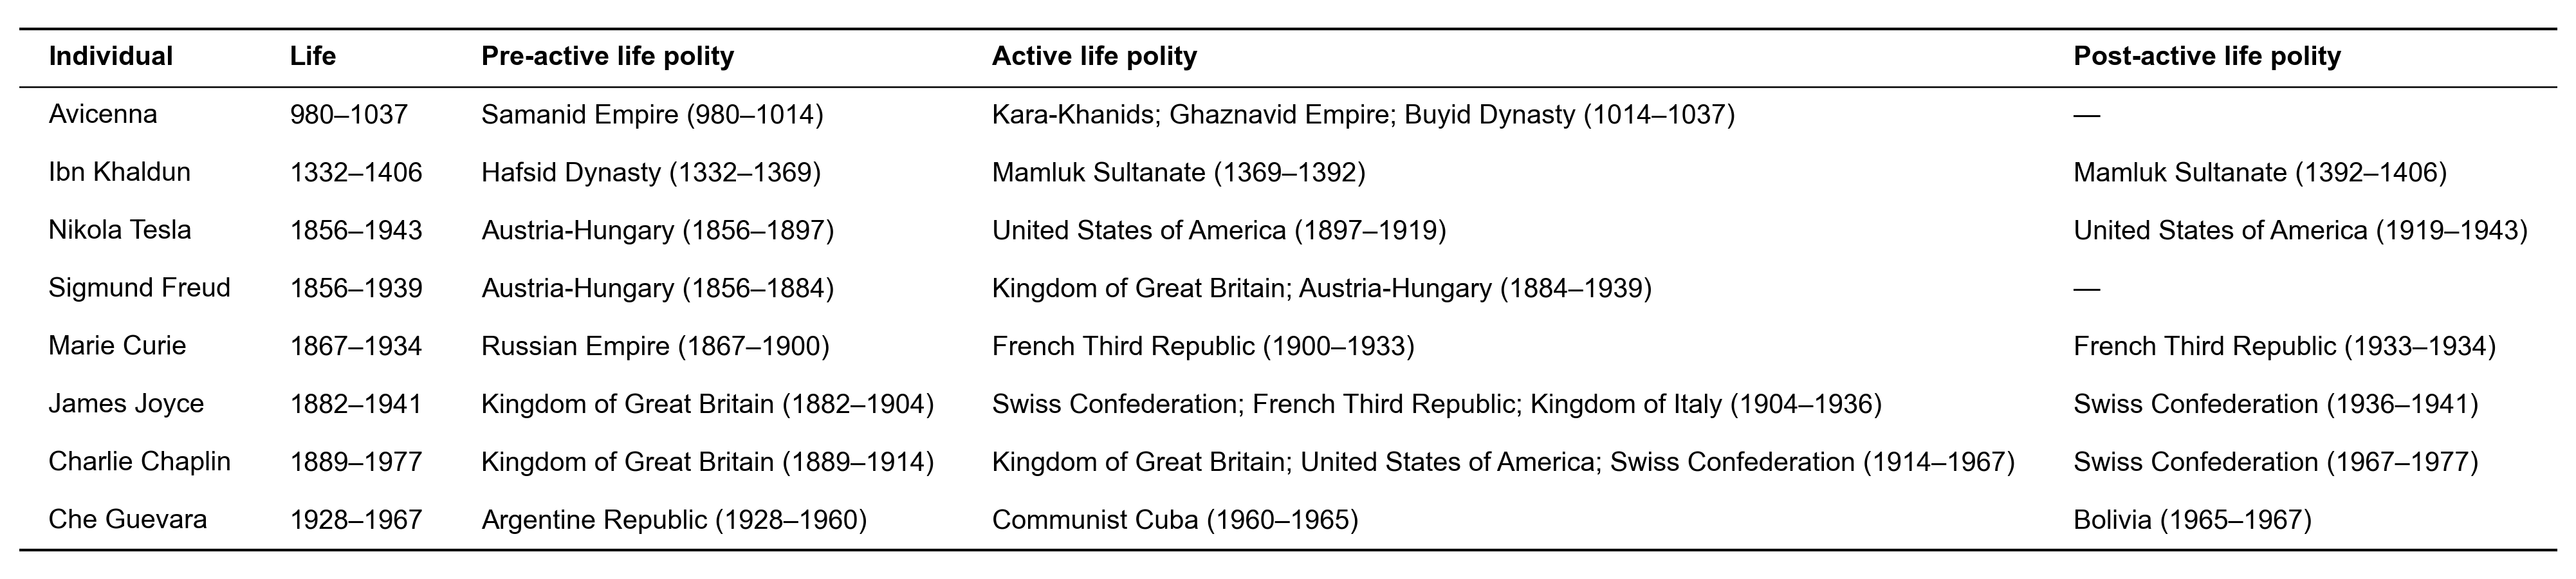

In [5]:
life_stage_table(MOVERS)

## Stages with a polity (Coverage paragraph)
An individual gets life stages when it has a birth year, a death year and an active life that overlaps its lifetime once clipped to it. The active stage always exists; the pre-active stage only when the active life starts after the birth year, the post-active stage only when it ends before the death year. A stage has a polity when its list in `individual_enriched` is not empty; read with `len()` only, the nested polity struct is not unnested.

In [6]:
coverage = connection.sql('''
    WITH lives AS (
        SELECT birth_date.year AS birth, death_date.year AS death,
               greatest(start_of_active_life.year, birth_date.year) AS start_active,
               least(end_of_active_life.year, death_date.year) AS end_active,
               len(pre_active_life_polity) > 0 AS pre_active, len(active_life_polity) > 0 AS active, len(post_active_life_polity) > 0 AS post_active
        FROM individual_enriched
        WHERE birth_date.year IS NOT NULL AND death_date.year IS NOT NULL AND start_of_active_life.year IS NOT NULL
    )
    SELECT count(*) AS individuals,
           count(*) FILTER (WHERE birth < start_active) AS pre_active_stages,
           count(*) FILTER (WHERE birth < start_active AND pre_active) AS pre_active_found,
           count(*) AS active_stages,
           count(*) FILTER (WHERE active) AS active_found,
           count(*) FILTER (WHERE end_active < death) AS post_active_stages,
           count(*) FILTER (WHERE end_active < death AND post_active) AS post_active_found
    FROM lives WHERE start_active <= end_active
''').pl().row(0, named=True)
cultura = connection.sql('SELECT count(*) FROM individual_enriched').fetchone()[0]
print(f"{coverage['individuals']:,} individuals with life stages ({100 * coverage['individuals'] / cultura:.1f}% of {cultura:,})")
for stage in STAGES:
    print(f"{stage}: {coverage[stage + '_stages']:,} stages, polity found for {100 * coverage[stage + '_found'] / coverage[stage + '_stages']:.1f}%")
assert coverage['individuals'] == stages['qid'].n_unique()


3,795,438 individuals with life stages (29.2% of 13,002,897)
pre_active: 3,790,619 stages, polity found for 71.0%
active: 3,795,438 stages, polity found for 70.9%
post_active: 2,984,857 stages, polity found for 70.8%
